# Visualizing the Fourier Transform with ManimGL

This notebook explains the mathematics behind the **Fourier Transform** and pairs it with a `manimgl` animation of the *winding machine* intuition.

**DO NOT TOUCH THIS NOTEBOOK FOR NOW**

## 1. The Core Idea: Decomposing Signals

Any periodic (or well-behaved) signal $g(t)$ can be represented as a sum of pure sinusoidal waves of different frequencies, amplitudes, and phases.

For our example, we construct a signal with two pure frequencies ($2\text{ Hz}$ and $3\text{ Hz}$) plus a constant DC offset:

$$g(t) = 1.5 + 0.8\cos(2\pi \cdot 2t) + 0.5\cos(2\pi \cdot 3t)$$

## 2. Euler's Formula & The Winding Machine

To detect whether a specific frequency $f$ is present in $g(t)$, we wrap the signal around the origin in the complex plane at a winding frequency $f$ using **Euler's formula**:

$$e^{-2\pi i f t} = \cos(2\pi f t) - i\sin(2\pi f t)$$

Multiplying $g(t)$ by $e^{-2\pi i f t}$ maps each time value $t$ to a point in the complex plane at:
- **Distance (radius):** $g(t)$
- **Angle (clockwise):** $2\pi f t$ radians

### Center of Mass
For most winding frequencies $f$, the wrapped curve is roughly balanced around the origin, so its **center of mass** stays near $0$. When $f$ matches a true frequency inside $g(t)$, all the peaks align on one side of the origin, pulling the center of mass sharply away from zero:

$$\text{Center of Mass}(f) = \frac{1}{T} \int_{0}^{T} g(t) e^{-2\pi i f t} \, dt$$

## 3. The Continuous Fourier Transform

Removing the $\frac{1}{T}$ scaling factor and extending the time interval to $(-\infty, \infty)$ yields the **Continuous Fourier Transform**:

$$\hat{g}(f) = \int_{-\infty}^{\infty} g(t) e^{-2\pi i f t} \, dt$$

- **Real part** $\operatorname{Re}(\hat{g}(f))$: measures correlation with cosines ($\cos(2\pi f t)$).
- **Imaginary part** $\operatorname{Im}(\hat{g}(f))$: measures correlation with sines ($-\sin(2\pi f t)$).
- **Magnitude** $|\hat{g}(f)|$: gives the overall strength of frequency $f$ regardless of phase.

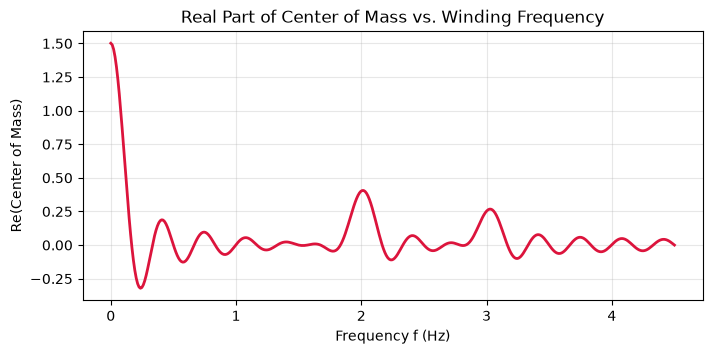

In [1]:
# Verify the math numerically before rendering the ManimGL animation
import numpy as np
import matplotlib.pyplot as plt

t = np.linspace(0, 3.0, 1000)
g = 1.5 + 0.8 * np.cos(2 * np.pi * 2.0 * t) + 0.5 * np.cos(2 * np.pi * 3.0 * t)

freqs = np.linspace(0, 4.5, 400)
com = [np.mean(g * np.exp(-2j * np.pi * f * t)) for f in freqs]

plt.figure(figsize=(8, 3.5))
plt.plot(freqs, np.real(com), color='crimson', lw=2)
plt.title('Real Part of Center of Mass vs. Winding Frequency')
plt.xlabel('Frequency f (Hz)')
plt.ylabel('Re(Center of Mass)')
plt.grid(True, alpha=0.3)
plt.show()

## 4. Render and Embed the `manimgl` Visualization

Make sure `fourier_viz.py` is in the same directory as this notebook. The cell below renders the animation to an `.mp4` file and embeds it directly in the output.

In [ ]:
import subprocess
from IPython.display import Video

# Render the scene to video using manimgl
subprocess.run([
    'manimgl', 'fourier_viz.py', 'FourierWindingMachine',
    '-w', '--file_name', 'fourier_winding.mp4'
], check=True)

# Display the rendered video inside the notebook
Video('videos/fourier_winding.mp4', embed=True, width=800)